# 📊 Phase 3 — Exploratory Data Analysis (EDA)
## PwC Technology Consulting | TelcoMax Customer Churn Engagement

**Objective:** Diagnose the root causes of customer attrition for TelcoMax Inc., uncovering behavioral patterns, service adoption bottlenecks, and contract dynamics across 7,043 customer accounts.

---

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.autolayout'] = True

DATA_PATH = os.path.join("..", "data", "processed", "telco_churn_cleaned.csv")
df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded. Records: {df.shape[0]:,}, Dimensions: {df.shape[1]}")

Dataset successfully loaded. Records: 7,043, Dimensions: 27


### Section 1: Data Schema & Quality Validation
Inspect structure, summary statistics, and verify zero null values following the SQL cleaning pipeline.

In [2]:
print("Missing Values Check:")
print(df.isnull().sum()[df.isnull().sum() > 0])
if df.isnull().sum().sum() == 0:
    print(">>> Verified: 0 missing values across all columns.")

df[['tenure', 'MonthlyCharges', 'TotalCharges', 'total_services_count', 'avg_monthly_spend']].describe().round(2)

Missing Values Check:
Series([], dtype: int64)
>>> Verified: 0 missing values across all columns.


,tenure,MonthlyCharges,TotalCharges,total_services_count,avg_monthly_spend
count,7043.00,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,2.04,64.76
std,24.56,30.09,2266.79,1.85,30.19
min,0.00,18.25,0.00,0.00,13.78
25%,9.00,35.50,398.55,0.00,35.94
50%,29.00,70.35,1394.55,2.00,70.34
75%,55.00,89.85,3786.60,3.00,90.17
max,72.00,118.75,8684.80,6.00,121.40


### Section 2: Univariate Analysis
Examine individual variable distributions across customer tenure, billing amounts, contract formats, and services.

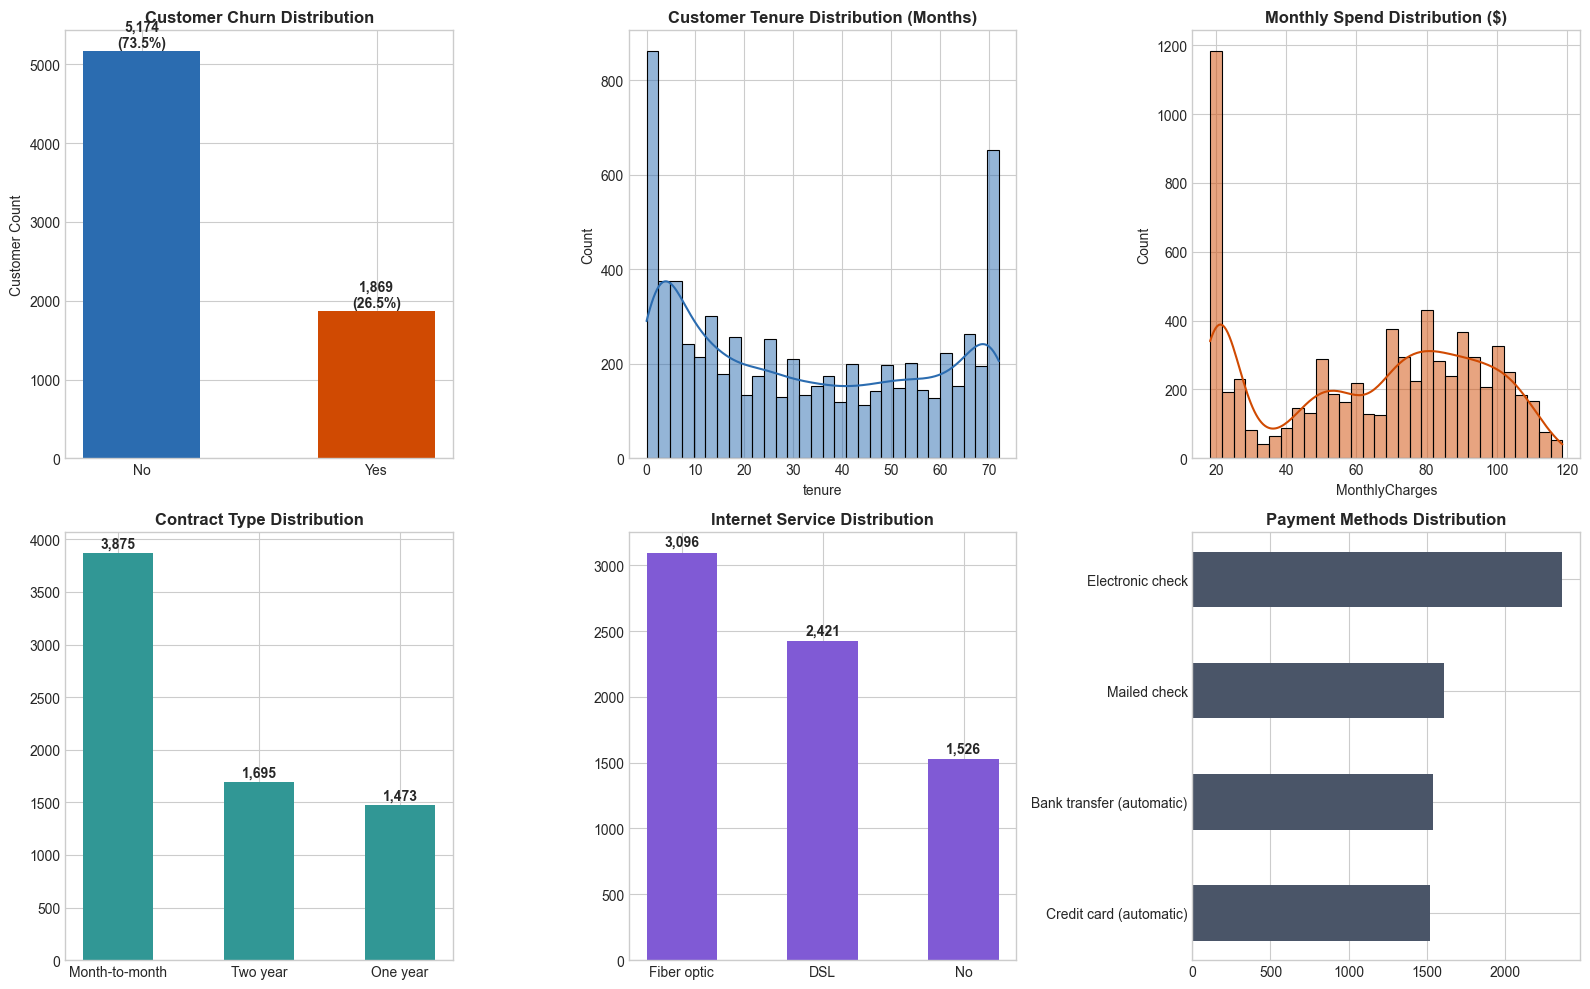

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Churn Distribution
churn_cnt = df['Churn'].value_counts()
axes[0, 0].bar(churn_cnt.index, churn_cnt.values, color=['#2B6CB0', '#D04A02'], width=0.5)
for i, v in enumerate(churn_cnt.values):
    axes[0, 0].text(i, v + 50, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
axes[0, 0].set_title("Customer Churn Distribution")
axes[0, 0].set_ylabel("Customer Count")

# 2. Tenure Distribution
sns.histplot(df['tenure'], bins=30, kde=True, color='#2B6CB0', ax=axes[0, 1])
axes[0, 1].set_title("Customer Tenure Distribution (Months)")

# 3. Monthly Charges Distribution
sns.histplot(df['MonthlyCharges'], bins=30, kde=True, color='#D04A02', ax=axes[0, 2])
axes[0, 2].set_title("Monthly Spend Distribution ($)")

# 4. Contract Types
c_cnt = df['Contract'].value_counts()
axes[1, 0].bar(c_cnt.index, c_cnt.values, color='#319795', width=0.5)
for i, v in enumerate(c_cnt.values):
    axes[1, 0].text(i, v + 50, f"{v:,}", ha='center', fontweight='bold')
axes[1, 0].set_title("Contract Type Distribution")

# 5. Internet Service Architecture
inet_cnt = df['InternetService'].value_counts()
axes[1, 1].bar(inet_cnt.index, inet_cnt.values, color='#805AD5', width=0.5)
for i, v in enumerate(inet_cnt.values):
    axes[1, 1].text(i, v + 50, f"{v:,}", ha='center', fontweight='bold')
axes[1, 1].set_title("Internet Service Distribution")

# 6. Payment Channels
pay_cnt = df['PaymentMethod'].value_counts()
axes[1, 2].barh(pay_cnt.index, pay_cnt.values, color='#4A5568', height=0.5)
axes[1, 2].set_title("Payment Methods Distribution")
axes[1, 2].invert_yaxis()

plt.tight_layout()
plt.show()

### Section 3: Bivariate Analysis (Correlations with Churn)
Deep-dive into relationship between key customer characteristics and likelihood to churn.

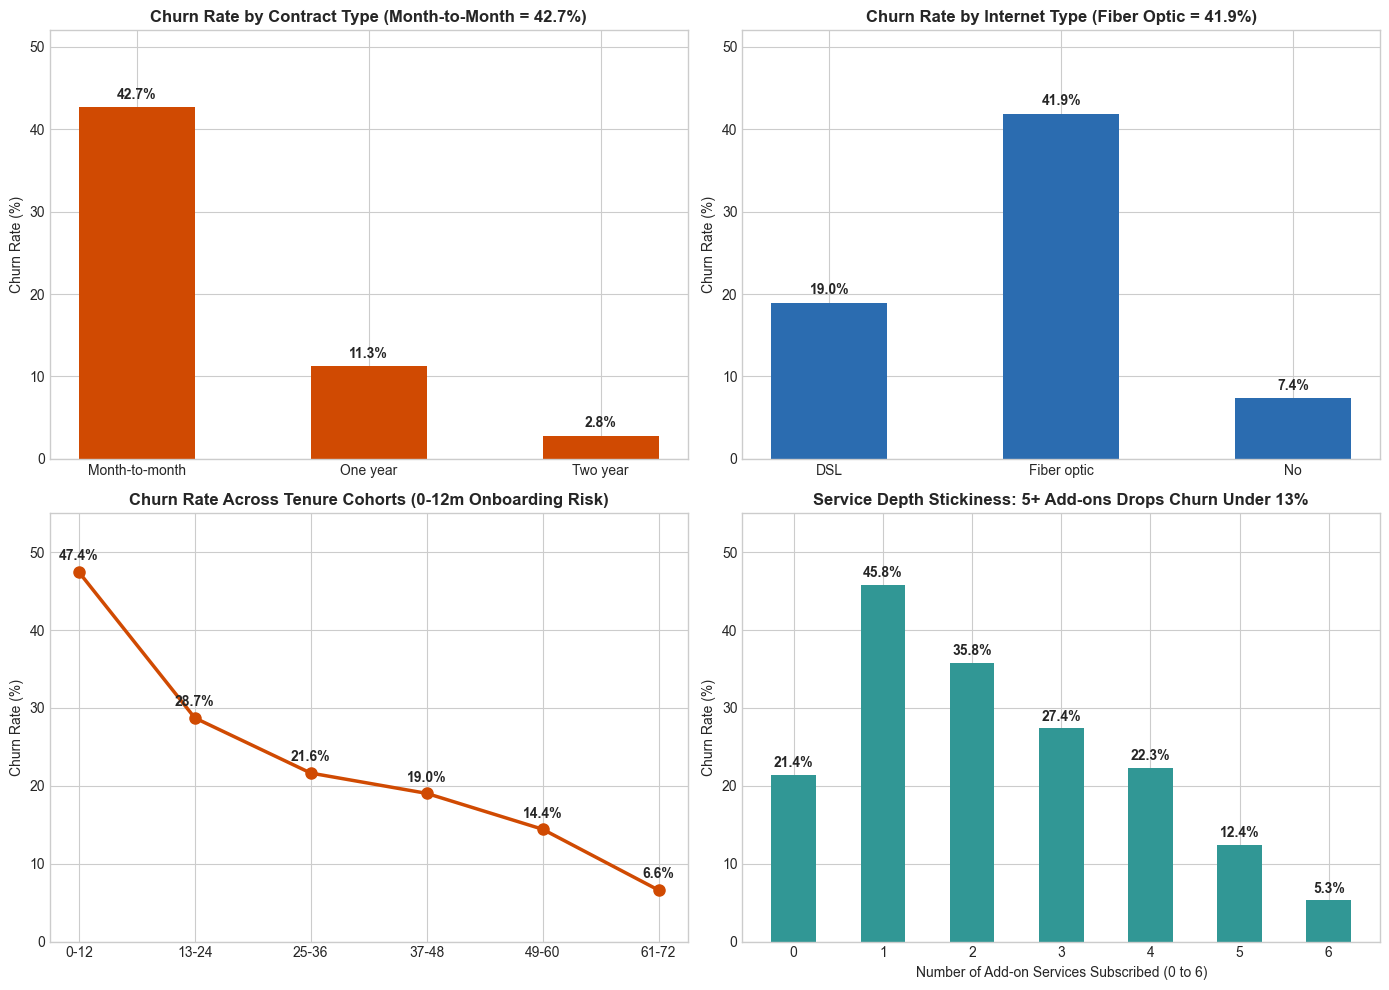

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Churn by Contract
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
bars1 = axes[0, 0].bar(contract_churn.index, contract_churn.values, color='#D04A02', width=0.5)
for bar in bars1:
    h = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha='center', fontweight='bold')
axes[0, 0].set_title("Churn Rate by Contract Type (Month-to-Month = 42.7%)")
axes[0, 0].set_ylabel("Churn Rate (%)")
axes[0, 0].set_ylim(0, 52)

# 2. Churn by Internet Service
inet_churn = df.groupby('InternetService')['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
bars2 = axes[0, 1].bar(inet_churn.index, inet_churn.values, color='#2B6CB0', width=0.5)
for bar in bars2:
    h = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha='center', fontweight='bold')
axes[0, 1].set_title("Churn Rate by Internet Type (Fiber Optic = 41.9%)")
axes[0, 1].set_ylabel("Churn Rate (%)")
axes[0, 1].set_ylim(0, 52)

# 3. Churn by Tenure Cohort
tenure_churn = df.groupby('tenure_group', observed=False)['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
axes[1, 0].plot(tenure_churn.index, tenure_churn.values, marker='o', color='#D04A02', linewidth=2.5, markersize=8)
for i, txt in enumerate(tenure_churn.values):
    axes[1, 0].annotate(f"{txt:.1f}%", (tenure_churn.index[i], txt + 1.5), ha='center', fontweight='bold')
axes[1, 0].set_title("Churn Rate Across Tenure Cohorts (0-12m Onboarding Risk)")
axes[1, 0].set_ylabel("Churn Rate (%)")
axes[1, 0].set_ylim(0, 55)

# 4. Churn by Total Services Count
serv_churn = df.groupby('total_services_count')['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
bars4 = axes[1, 1].bar(serv_churn.index.astype(str), serv_churn.values, color='#319795', width=0.5)
for bar in bars4:
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha='center', fontweight='bold')
axes[1, 1].set_title("Service Depth Stickiness: 5+ Add-ons Drops Churn Under 13%")
axes[1, 1].set_xlabel("Number of Add-on Services Subscribed (0 to 6)")
axes[1, 1].set_ylabel("Churn Rate (%)")
axes[1, 1].set_ylim(0, 55)

plt.tight_layout()
plt.show()

### Section 4: Correlation Heatmap
Evaluate linear correlation between numeric attributes, encoded business segments, and customer attrition.

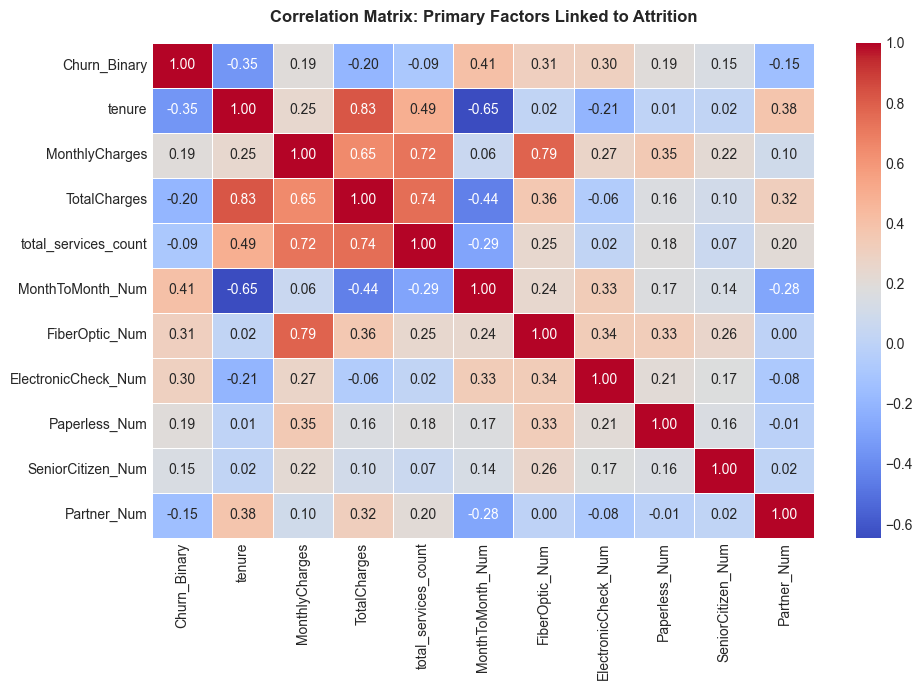

In [5]:
df_corr = df.copy()
df_corr["Churn_Binary"] = (df_corr["Churn"] == "Yes").astype(int)
df_corr["SeniorCitizen_Num"] = (df_corr["SeniorCitizen"] == "Yes").astype(int)
df_corr["Partner_Num"] = (df_corr["Partner"] == "Yes").astype(int)
df_corr["Dependents_Num"] = (df_corr["Dependents"] == "Yes").astype(int)
df_corr["Paperless_Num"] = (df_corr["PaperlessBilling"] == "Yes").astype(int)
df_corr["MonthToMonth_Num"] = (df_corr["Contract"] == "Month-to-month").astype(int)
df_corr["FiberOptic_Num"] = (df_corr["InternetService"] == "Fiber optic").astype(int)
df_corr["ElectronicCheck_Num"] = (df_corr["PaymentMethod"] == "Electronic check").astype(int)

heatmap_cols = [
    "Churn_Binary", "tenure", "MonthlyCharges", "TotalCharges", 
    "total_services_count", "MonthToMonth_Num", "FiberOptic_Num", 
    "ElectronicCheck_Num", "Paperless_Num", "SeniorCitizen_Num", "Partner_Num"
]

plt.figure(figsize=(10, 7))
sns.heatmap(df_corr[heatmap_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix: Primary Factors Linked to Attrition", pad=15)
plt.show()

### Section 5: Key Business Insights Summary

> #### 📌 Strategic Findings for Client Leadership
> 1. **Contract Structure is the Single Largest Churn Lever:** Month-to-month accounts experience **42.7% churn**, accounting for **88.5% of all churned subscribers** and **$1.45M in annual lost revenue**. By contrast, two-year contracts churn at only **2.8%**.
> 2. **Early Tenure Vulnerability (The 90-Day Cliff):** **47.4%** of customers in their first 12 months leave the company, representing **55.5% (1,037 accounts)** of all churn.
> 3. **Fiber Optic Attrition Disparity:** Fiber optic subscribers churn at **41.9%** (vs. 19.0% for DSL), despite paying higher monthly rates (~$91/mo vs ~$58/mo), indicating service reliability or pricing sensitivity.
> 4. **Payment Channel Friction:** Customers utilizing **Electronic Check** show **45.3% churn**, compared to ~15.2% for automated credit cards, highlighting lack of auto-pay stickiness.
> 5. **Protective Power of Service Bundling:** Customers holding 5+ add-on services churn at **<13%**, while customers with only 1 add-on churn at **45.8%**, proving multi-product integration dramatically increases switching barriers.